# Lab 08 - Phân cụm K-Means (6 bài tập)

- **Môn học** Học máy ứng dụng
- **Giảng viên** ThS. Nguyễn Thái Anh
- **Sinh viên** Huỳnh Hữu Phúc
- **MSSV** 2474802010314

## Bài 1. Tự tính silhouette

**Đề bài**

Viết hàm `silhouette_mot_diem(X, nhan, i)` bằng NumPy để tính `a`, `b`, `s`. Tính cho 210 khách với `K=5`, so trung bình với `silhouette_score` và chỉ vị trí khách có `s` thấp nhất trên hình phân cụm.

Silhouette trung bình tự tính:   0.722706
Silhouette trung bình thư viện: 0.722706
Khách có s nhỏ nhất: chỉ số dòng 113 (từ 0), cụm 2, tuổi 38.
Thu nhập 25.4 triệu/tháng, điểm chi tiêu 41.
a = 0.917758, b = 0.944750, s = 0.028571
Khoảng cách trung bình đến cụm 0: 2.363555
Khoảng cách trung bình đến cụm 1: 0.944750
Khoảng cách trung bình đến cụm 3: 1.969795
Khoảng cách trung bình đến cụm 4: 1.613442
Đã lưu figures/silhouette_khach_hang.png


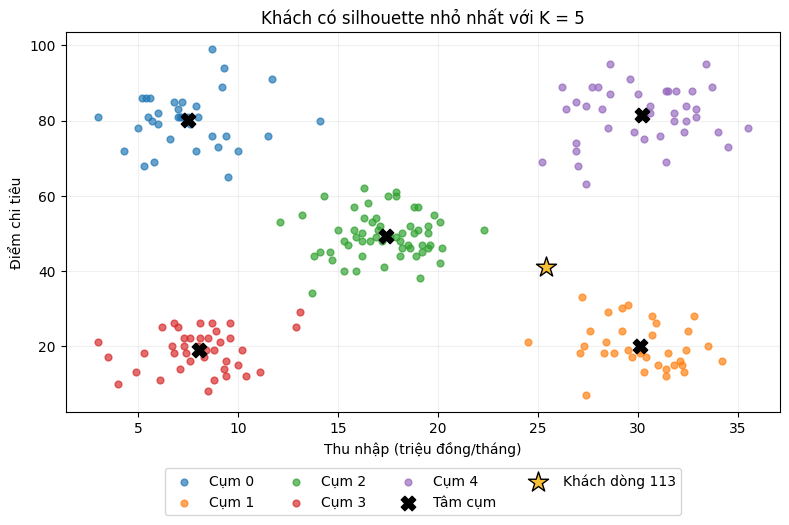

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


def silhouette_mot_diem(X, nhan, i):
    """Trả về a, b và silhouette của điểm i với khoảng cách Euclid."""
    cung_cum = nhan == nhan[i]
    cung_cum[i] = False
    khoang_cach = np.linalg.norm(X - X[i], axis=1)
    cum_khac = np.unique(nhan[nhan != nhan[i]])
    b = min(khoang_cach[nhan == cum].mean() for cum in cum_khac)
    if not cung_cum.any():
        return 0.0, b, 0.0
    a = khoang_cach[cung_cum].mean()
    s = (b - a) / max(a, b) if max(a, b) > 0 else 0.0
    return a, b, s


khach_hang = pd.read_csv("data/khach_hang.csv")
dac_trung = khach_hang[["thu_nhap", "diem_chi_tieu"]]
chuan_hoa = StandardScaler().fit(dac_trung)
X_chuan = chuan_hoa.transform(dac_trung)
mo_hinh = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_chuan)
nhan = mo_hinh.labels_
cac_chi_so = np.array([
    silhouette_mot_diem(X_chuan, nhan, i) for i in range(len(X_chuan))
])
sil_tu_tinh = cac_chi_so[:, 2].mean()
sil_thu_vien = silhouette_score(X_chuan, nhan)
np.testing.assert_allclose(sil_tu_tinh, sil_thu_vien, atol=1e-12)

vi_tri_min = int(cac_chi_so[:, 2].argmin())
khach_min = khach_hang.iloc[vi_tri_min]
a, b, s = cac_chi_so[vi_tri_min]
print(f"Silhouette trung bình tự tính:   {sil_tu_tinh:.6f}")
print(f"Silhouette trung bình thư viện: {sil_thu_vien:.6f}")
print(f"Khách có s nhỏ nhất: chỉ số dòng {vi_tri_min} (từ 0), "
      f"cụm {nhan[vi_tri_min]}, tuổi {khach_min['tuoi']:.0f}.")
print(f"Thu nhập {khach_min['thu_nhap']:.1f} triệu/tháng, "
      f"điểm chi tiêu {khach_min['diem_chi_tieu']:.0f}.")
print(f"a = {a:.6f}, b = {b:.6f}, s = {s:.6f}")
for cum in np.unique(nhan):
    if cum == nhan[vi_tri_min]:
        continue
    khoang_cach_tb = np.linalg.norm(X_chuan[nhan == cum] - X_chuan[vi_tri_min], axis=1).mean()
    print(f"Khoảng cách trung bình đến cụm {cum}: {khoang_cach_tb:.6f}")

tam_goc = chuan_hoa.inverse_transform(mo_hinh.cluster_centers_)
fig, ax = plt.subplots(figsize=(8.0, 5.4))
for cum in np.unique(nhan):
    thanh_vien = dac_trung[nhan == cum]
    ax.scatter(thanh_vien["thu_nhap"], thanh_vien["diem_chi_tieu"],
               s=24, alpha=0.68, label=f"Cụm {cum}")
ax.scatter(tam_goc[:, 0], tam_goc[:, 1], marker="X", s=108, c="black",
           label="Tâm cụm", zorder=3)
ax.scatter(khach_min["thu_nhap"], khach_min["diem_chi_tieu"],
           marker="*", s=230, c="#f5bf36", edgecolor="black", zorder=4,
           label=f"Khách dòng {vi_tri_min}")
ax.set(xlabel="Thu nhập (triệu đồng/tháng)", ylabel="Điểm chi tiêu",
       title="Khách có silhouette nhỏ nhất với K = 5")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=4)
ax.grid(alpha=0.18)
fig.tight_layout()
thu_muc_hinh = Path("figures")
thu_muc_hinh.mkdir(exist_ok=True)
fig.savefig(thu_muc_hinh / "silhouette_khach_hang.png", dpi=150, bbox_inches="tight")
print("Đã lưu figures/silhouette_khach_hang.png")
plt.show()

**Giải thích và nhận xét**

Tính trên hai cột đã chuẩn hoá và dùng khoảng cách Euclid. Với điểm $i$, $a$ là khoảng cách trung bình đến **các điểm khác** trong cụm của nó. Với từng cụm khác, lấy trung bình khoảng cách từ $i$ đến toàn bộ điểm trong cụm đó. $b$ là giá trị nhỏ nhất trong các trung bình này. Silhouette của điểm là $s=(b-a)/\max(a,b)$. Với cụm chỉ có một mẫu, hàm gán $s=0$ theo quy ước của scikit-learn.

Nếu $s$ gần 1, điểm gần các thành viên cụm mình hơn rõ rệt. Nếu $s$ gần 0, hai khoảng cách trung bình gần bằng nhau. Nếu $s<0$, trung bình khoảng cách tới một cụm khác nhỏ hơn trung bình khoảng cách tới cụm hiện tại. Trung bình trên 210 khách bằng **0,722706**, khớp với `silhouette_score`.

**Khách có silhouette thấp nhất** ở chỉ số dòng **113** tính từ 0 (bản ghi dữ liệu thứ 114). Khách 38 tuổi, thu nhập **25,4 triệu đồng/tháng**, điểm chi tiêu **41**, được gán vào cụm **2**. Ta có $a=0.917758$, $b=0.944750$ và $s=0.028571$. Cụm cạnh tranh là cụm **1**. Trên hình, ngôi sao ở bên phải nhóm thu nhập vừa và phía trên nhóm thu nhập cao chi ít. Hai khoảng cách trung bình chỉ lệch khoảng 0,027 trên thang đã chuẩn hoá, giải thích vì sao điểm này khó phân nhóm.

## Bài 2. Thêm cột tuổi

**Đề bài**

Chuẩn hoá cả ba cột tuổi, thu nhập và điểm chi tiêu. Thử `K=2..10` theo silhouette rồi so tâm cụm với mô hình hai biến của mục 3.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

khach_hang = pd.read_csv("data/khach_hang.csv")
cot_hai_bien = ["thu_nhap", "diem_chi_tieu"]
cot_ba_bien = ["tuoi", *cot_hai_bien]

chuan_hoa_hai = StandardScaler().fit(khach_hang[cot_hai_bien])
X_hai_bien = chuan_hoa_hai.transform(khach_hang[cot_hai_bien])
mo_hinh_hai = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_hai_bien)
nhan_hai_bien = mo_hinh_hai.labels_

chuan_hoa_ba = StandardScaler().fit(khach_hang[cot_ba_bien])
X_ba_bien = chuan_hoa_ba.transform(khach_hang[cot_ba_bien])
ket_qua = {}
cac_mo_hinh = {}
for k in range(2, 11):
    mo_hinh = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_ba_bien)
    cac_mo_hinh[k] = mo_hinh
    ket_qua[k] = silhouette_score(X_ba_bien, mo_hinh.labels_)

bang_silhouette = pd.Series(ket_qua, name="Silhouette").rename_axis("K")
k_tot_nhat = bang_silhouette.idxmax()
mo_hinh_ba = cac_mo_hinh[k_tot_nhat]
print("Silhouette khi dùng cả tuổi, thu nhập và điểm chi tiêu")
print(bang_silhouette.to_string(float_format=lambda diem: f"{diem:.4f}"))
print(f"\nK tốt nhất với ba biến: {k_tot_nhat}")
print(f"Silhouette hai biến, K = 5: {silhouette_score(X_hai_bien, nhan_hai_bien):.4f}")

tam_hai = pd.DataFrame(
    chuan_hoa_hai.inverse_transform(mo_hinh_hai.cluster_centers_),
    columns=cot_hai_bien,
)
tam_hai.insert(0, "tuoi", khach_hang.groupby(nhan_hai_bien)["tuoi"].mean())
tam_hai["so_khach"] = np.bincount(nhan_hai_bien)
tam_ba = pd.DataFrame(
    chuan_hoa_ba.inverse_transform(mo_hinh_ba.cluster_centers_),
    columns=cot_ba_bien,
)
tam_ba["so_khach"] = np.bincount(mo_hinh_ba.labels_)

for ten, bang_tam in [("Hai biến (tuổi chỉ để mô tả)", tam_hai),
                      ("Ba biến (tuổi tham gia phân cụm)", tam_ba)]:
    print(f"\n{ten} — tâm cụm theo đơn vị gốc, sắp theo thu nhập")
    print(bang_tam.sort_values("thu_nhap").round(1).to_string())
print("\nSố khách chung giữa cụm cũ (hàng) và cụm mới (cột)")
print(pd.crosstab(nhan_hai_bien, mo_hinh_ba.labels_,
                  rownames=["Cụm hai biến"], colnames=["Cụm ba biến"]))
print(f"ARI giữa hai cách chia: {adjusted_rand_score(nhan_hai_bien, mo_hinh_ba.labels_):.4f}")

Silhouette khi dùng cả tuổi, thu nhập và điểm chi tiêu
K
2    0.3730
3    0.4220
4    0.4558
5    0.4808
6    0.4760
7    0.4627
8    0.4596
9    0.4622
10   0.4573

K tốt nhất với ba biến: 5
Silhouette hai biến, K = 5: 0.7227

Hai biến (tuổi chỉ để mô tả) — tâm cụm theo đơn vị gốc, sắp theo thu nhập
   tuoi  thu_nhap  diem_chi_tieu  so_khach
0  24.9       7.5           80.2        35
3  44.9       8.0           18.9        40
2  40.4      17.4           49.3        60
1  42.9      30.1           20.0        35
4  32.6      30.2           81.5        40

Ba biến (tuổi tham gia phân cụm) — tâm cụm theo đơn vị gốc, sắp theo thu nhập
   tuoi  thu_nhap  diem_chi_tieu  so_khach
0  44.9       8.0           18.9        40
1  25.1       8.5           77.6        39
4  41.6      17.6           49.2        57
2  42.9      30.1           20.0        35
3  32.1      30.3           82.0        39

Số khách chung giữa cụm cũ (hàng) và cụm mới (cột)
Cụm ba biến    0   1   2   3   4
Cụm hai biến      

**Giải thích và nhận xét**

Có thêm tuổi, silhouette trong lưới `K=2..10` vẫn cao nhất tại `K=5`, đạt `0.4808`, gần `0.4760` của `K=6`. Mô hình hai biến của mục 3 cho `0.7227`. Hai giá trị mô tả độ tách cụm trong hai không gian đặc trưng khác nhau.

Nhóm thu nhập thấp chi nhiều từ 35 tăng lên 39 khách. Tâm đổi từ `(7.5 triệu, 80.2 điểm)` sang `(8.5 triệu, 77.6 điểm)`, tuổi trung bình từ `24.9` lên `25.1`. Nhóm thu nhập vừa chi vừa từ 60 giảm còn 57 khách, tuổi trung bình từ `40.4` lên `41.6`. Hai nhóm chi ít giữ nguyên thành viên. Bảng chéo cho thấy 4 khách từ nhóm giữa chuyển sang nhóm thu nhập thấp chi nhiều, và 1 khách từ nhóm thu nhập cao chi nhiều chuyển vào nhóm giữa. `ARI=0.9357` cho thấy hai cách chia khá giống nhau, kể cả khi số cụm bị đánh lại.

## Bài 3. K-Means++ và khởi tạo ngẫu nhiên

**Đề bài**

So sánh `init="random"` và `init="k-means++"` trên khách hàng với `K=5`, `n_init=1` và 50 seed từ 0 đến 49. Đếm số lần đạt inertia 23,0 và giải thích cách khởi tạo nào ổn định hơn.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

khach_hang = pd.read_csv("data/khach_hang.csv")
dac_trung = ["thu_nhap", "diem_chi_tieu"]
X_chuan = StandardScaler().fit_transform(khach_hang[dac_trung])

cac_kieu_khoi_tao = ("random", "k-means++")
ket_qua = {}
for khoi_tao in cac_kieu_khoi_tao:
    inertia = []
    for seed in range(50):
        mo_hinh = KMeans(n_clusters=5, init=khoi_tao, n_init=1, random_state=seed)
        inertia.append(mo_hinh.fit(X_chuan).inertia_)
    ket_qua[khoi_tao] = inertia

inertia_theo_seed = pd.DataFrame(ket_qua).rename_axis("random_state")
print("Inertia sau từng lần chạy (in đến một chữ số thập phân)")
print(inertia_theo_seed.to_string(float_format=lambda diem: f"{diem:.1f}"))
print("\nĐếm mức 23.0 theo đúng độ làm tròn ở mục 5")
for khoi_tao, diem in inertia_theo_seed.items():
    so_lan_dat = int(np.count_nonzero(diem.round(1).to_numpy() == 23.0))
    print(f"{khoi_tao:9s}: {so_lan_dat}/50 đạt 23.0 ({so_lan_dat / 50:.0%}), "
          f"min = {diem.min():.2f}, trung vị = {diem.median():.2f}, "
          f"max = {diem.max():.2f}")

Inertia sau từng lần chạy (in đến một chữ số thập phân)
              random  k-means++
random_state                   
0               23.0       23.0
1               23.0       23.0
2               23.0       23.0
3               84.2       23.0
4               23.0       23.0
5               23.0       23.0
6               23.0       23.0
7               73.6       23.0
8              116.6       23.0
9               73.7       23.0
10              72.4       23.0
11              84.2       23.0
12              73.7       23.0
13              23.0       23.0
14              84.0       23.0
15             118.2       23.0
16              23.0       23.0
17             117.4       23.0
18              23.0       23.0
19              23.0       23.0
20             119.3       23.0
21              23.0       23.0
22              23.0       23.0
23              23.0       23.0
24              23.0       23.0
25              23.0       23.0
26              23.0       23.0
27              

**Giải thích và nhận xét**

Với cùng tập dữ liệu chuẩn hoá, `K=5`, `n_init=1` và các seed 0–49, khởi tạo **random đạt 30/50 lần (60%)**, còn **K-Means++ đạt 50/50 lần (100%)**. Đếm trên inertia làm tròn đến một chữ số thập phân như đề. Nghiệm tốt có inertia xấp xỉ `23.02`, được in là `23.0` theo quy tắc này. Inertia cao nhất của random là `204.05`.

Random có thể đặt nhiều tâm ban đầu trong cùng một nhóm, để nhóm khác thiếu tâm. Các bước gán và dời tâm chỉ cải thiện cách chia quanh vị trí hiện tại, nên thuật toán có thể hội tụ ở một nghiệm cục bộ với inertia cao. K-Means++ ưu tiên điểm xa các tâm đã chọn, dựa trên bình phương khoảng cách đến tâm gần nhất. Nhờ các tâm xuất phát trải rộng hơn, nó tìm được nghiệm tốt ổn định hơn trong 50 lần thử này. `n_init` xử lý một khía cạnh khác của khởi tạo bằng cách chạy nhiều lần và giữ lần có inertia thấp nhất.

## Bài 4. Lưu ảnh đã nén

**Đề bài**

Tạo bảng màu 16 màu cho `china.jpg`, lưu ảnh gốc và ảnh nén rồi so dung lượng. Lặp lại với ảnh hoa mẫu theo lựa chọn của bạn. Đường dẫn ảnh ở đầu phần chạy có thể đổi sang ảnh riêng và được đọc bằng `plt.imread`.

Ảnh mẫu china.jpg
Kích thước RGB: (427, 640, 3), số màu trong ảnh nén: 16
PNG gốc: figures/anh_goc.png (550,154 byte)
PNG nén: figures/anh_16_mau.png (134,509 byte)
Dung lượng gốc / nén: 4.09 lần
Sai lệch màu trung bình mỗi kênh RGB: 7.97/255

Ảnh hoa mẫu
Kích thước RGB: (427, 640, 3), số màu trong ảnh nén: 16
PNG gốc: figures/anh_hoa_goc.png (419,413 byte)
PNG nén: figures/anh_hoa_16_mau.png (55,634 byte)
Dung lượng gốc / nén: 7.54 lần
Sai lệch màu trung bình mỗi kênh RGB: 6.22/255



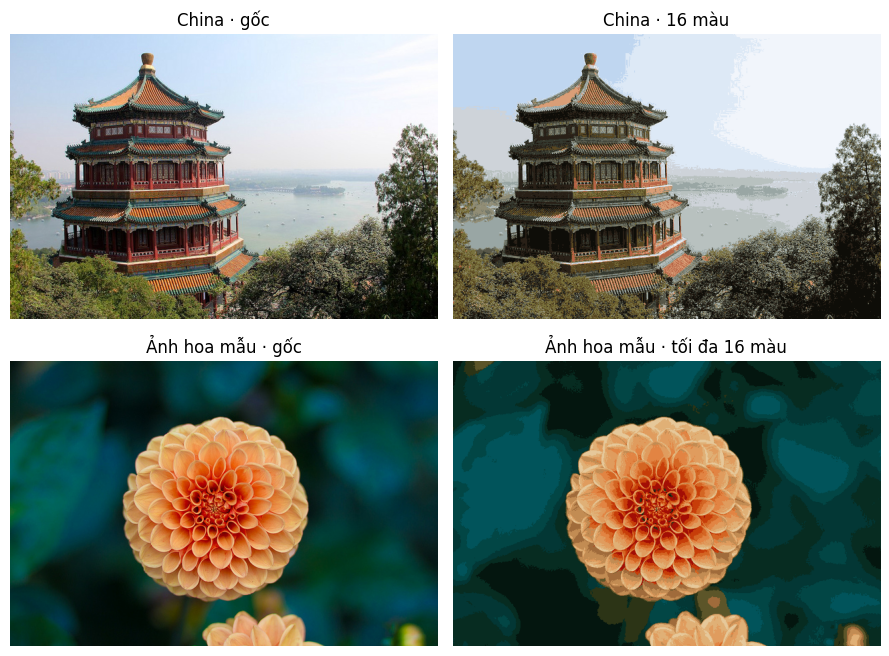

In [ ]:
from importlib.resources import files
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image


def luu_anh_16_mau(anh_doc, tep_goc, tep_nen):
    """Học bảng màu từ tối đa 5.000 pixel rồi lưu hai ảnh PNG RGB."""
    if anh_doc.ndim == 2:
        anh_doc = np.repeat(anh_doc[:, :, None], 3, axis=2)
    anh_rgb = anh_doc[:, :, :3]  # Bỏ alpha khi đầu vào là PNG RGBA.
    rgb = anh_rgb.astype(np.float64)
    if np.issubdtype(anh_rgb.dtype, np.integer):
        rgb /= np.iinfo(anh_rgb.dtype).max

    diem_anh = rgb.reshape(-1, 3)
    rng = np.random.default_rng(0)
    mau_hoc = diem_anh[rng.choice(len(diem_anh), min(5000, len(diem_anh)), replace=False)]
    so_cum = min(16, len(np.unique(mau_hoc, axis=0)))
    mo_hinh = KMeans(n_clusters=so_cum, n_init=4, random_state=0).fit(mau_hoc)
    nhan = mo_hinh.predict(diem_anh)
    anh_nen = mo_hinh.cluster_centers_[nhan].reshape(rgb.shape)
    anh_goc_png = np.rint(np.clip(rgb, 0, 1) * 255).astype(np.uint8)
    anh_nen_png = np.rint(np.clip(anh_nen, 0, 1) * 255).astype(np.uint8)
    plt.imsave(tep_goc, anh_goc_png)
    plt.imsave(tep_nen, anh_nen_png)

    so_mau_png = len(np.unique(anh_nen_png.reshape(-1, 3), axis=0))
    sai_lech = np.abs(anh_nen - rgb).mean() * 255
    dung_luong_goc = tep_goc.stat().st_size
    dung_luong_nen = tep_nen.stat().st_size
    print(f"Kích thước RGB: {anh_nen_png.shape}, số màu trong ảnh nén: {so_mau_png}")
    print(f"PNG gốc: {tep_goc.as_posix()} ({dung_luong_goc:,} byte)")
    print(f"PNG nén: {tep_nen.as_posix()} ({dung_luong_nen:,} byte)")
    print(f"Dung lượng gốc / nén: {dung_luong_goc / dung_luong_nen:.2f} lần")
    print(f"Sai lệch màu trung bình mỗi kênh RGB: {sai_lech:.2f}/255\n")
    return anh_goc_png, anh_nen_png


thu_muc_hinh = Path("figures")
thu_muc_hinh.mkdir(exist_ok=True)
anh_china = load_sample_image("china.jpg")
duong_dan_anh_rieng = None  # Ví dụ: Path("data/anh_cua_minh.png")
if duong_dan_anh_rieng is None:
    tep_hinh_hoa = files("sklearn.datasets").joinpath("images", "flower.jpg")
    with tep_hinh_hoa.open("rb") as tep:
        anh_thu_hai = plt.imread(tep, format="jpg")
    ten_anh_thu_hai = "Ảnh hoa mẫu"
    tien_to_thu_hai = "anh_hoa"
else:
    anh_thu_hai = plt.imread(duong_dan_anh_rieng)
    ten_anh_thu_hai = "Ảnh riêng"
    tien_to_thu_hai = "anh_rieng"

print("Ảnh mẫu china.jpg")
goc_china, nen_china = luu_anh_16_mau(
    anh_china, thu_muc_hinh / "anh_goc.png", thu_muc_hinh / "anh_16_mau.png"
)
print(ten_anh_thu_hai)
goc_thu_hai, nen_thu_hai = luu_anh_16_mau(
    anh_thu_hai, thu_muc_hinh / f"{tien_to_thu_hai}_goc.png",
    thu_muc_hinh / f"{tien_to_thu_hai}_16_mau.png",
)

fig, truc = plt.subplots(2, 2, figsize=(9.0, 6.8))
for ax, anh, tieu_de in zip(
    truc.flat,
    (goc_china, nen_china, goc_thu_hai, nen_thu_hai),
    ("China · gốc", "China · 16 màu", f"{ten_anh_thu_hai} · gốc",
     f"{ten_anh_thu_hai} · tối đa 16 màu"),
):
    ax.imshow(anh)
    ax.set_title(tieu_de)
    ax.axis("off")
fig.tight_layout()
plt.show()

**Giải thích và nhận xét**

Hai ảnh nén đều có kích thước `(427, 640, 3)` và đúng 16 màu RGB. So hai file PNG của cùng một ảnh, China giảm từ **550.154 xuống 134.509 byte** (gốc lớn gấp **4,09 lần**). Ảnh hoa giảm từ **419.413 xuống 55.634 byte** (gốc lớn gấp **7,54 lần**). PNG còn mã hoá theo mức độ lặp của hình và có phần thông tin định dạng, nên tỷ lệ file thay đổi theo ảnh.

Để chạy với ảnh riêng, sao chép ảnh JPG hoặc PNG vào `data/`, sau đó đặt `duong_dan_anh_rieng = Path("data/anh_cua_minh.png")` với tên file thực tế. Code đọc ảnh bằng `plt.imread`, lấy ba kênh RGB nếu có alpha và lưu cặp `anh_rieng_goc.png` / `anh_rieng_16_mau.png`. Với ảnh có ít màu, hàm dùng tối đa 16 màu.

## Bài 5. DBSCAN trên hai vầng trăng

**Đề bài**

Chạy `DBSCAN(min_samples=5)` trên hai vầng trăng với `eps` bằng 0,2, 0,3 và 0,4. Đếm số cụm và nhiễu, so với K-Means, đồng thời giải thích vai trò của `eps`.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score

hai_vang_trang = pd.read_csv("data/hai_vang_trang.csv")
toa_do = hai_vang_trang[["x1", "x2"]]
nhan_that = hai_vang_trang["nhan"].to_numpy()


def ty_le_khop_hai_cum(nhan_that, nhan_cum):
    """Căn nhãn của hai cụm, tính tỷ lệ khớp trên toàn bộ điểm."""
    duoc_gan_cum = nhan_cum != -1
    cac_cum = np.unique(nhan_cum[duoc_gan_cum])
    if len(cac_cum) != 2:
        return np.nan
    that = nhan_that[duoc_gan_cum]
    doan = (nhan_cum[duoc_gan_cum] == cac_cum[1]).astype(int)
    so_khop = max(np.count_nonzero(doan == that), np.count_nonzero(1 - doan == that))
    return so_khop / len(nhan_that)


kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
cac_nhan = {"K-Means K=2": kmeans.fit_predict(toa_do)}
for eps in (0.2, 0.3, 0.4):
    dbscan = DBSCAN(eps=eps, min_samples=5)
    cac_nhan[f"DBSCAN eps={eps}"] = dbscan.fit_predict(toa_do)

dong_ket_qua = []
for ten, nhan_cum in cac_nhan.items():
    la_nhieu = nhan_cum == -1
    dong_ket_qua.append({
        "Mô hình": ten,
        "Số cụm": len(np.unique(nhan_cum[~la_nhieu])),
        "Nhiễu": int(la_nhieu.sum()),
        "ARI toàn bộ": adjusted_rand_score(nhan_that, nhan_cum),
        "Tỷ lệ khớp hai cụm": ty_le_khop_hai_cum(nhan_that, nhan_cum),
    })
print(pd.DataFrame(dong_ket_qua).to_string(
    index=False, na_rep="—", float_format=lambda diem: f"{diem:.4f}",
))
print("\nBảng đếm giữa nhãn thật và cụm DBSCAN")
for ten, nhan_cum in list(cac_nhan.items())[1:]:
    print(f"\n{ten}")
    print(pd.crosstab(nhan_that, nhan_cum, rownames=["Nhãn thật"], colnames=["Cụm"]))

       Mô hình  Số cụm  Nhiễu  ARI toàn bộ  Tỷ lệ khớp hai cụm
   K-Means K=2       2      0       0.2475              0.7500
DBSCAN eps=0.2       1     40      -0.0014                   —
DBSCAN eps=0.3       1     10       0.0012                   —
DBSCAN eps=0.4       1      3      -0.0001                   —

Bảng đếm giữa nhãn thật và cụm DBSCAN

DBSCAN eps=0.2
Cụm        -1    0
Nhãn thật         
0          19  131
1          21  129

DBSCAN eps=0.3
Cụm        -1    0
Nhãn thật         
0           8  142
1           2  148

DBSCAN eps=0.4
Cụm        -1    0
Nhãn thật         
0           2  148
1           1  149


**Giải thích và nhận xét**

Cả ba `eps` đều tìm 1 cụm, với số điểm nhiễu lần lượt **40, 10, 3**. Bảng chéo cho thấy các điểm thuộc cả hai vầng trăng thật đều nằm trong cụm duy nhất. ARI trên toàn bộ điểm (coi `-1` là một nhãn riêng khi chấm) gần 0 ở cả ba cấu hình. K-Means tìm 2 cụm, đạt ARI `0.2475` và khớp `0.7500` sau khi xét cả hai cách gán nhãn. Vì DBSCAN chỉ có một cụm, cột tỷ lệ khớp hai cụm để trống.

`eps` là bán kính lân cận. Với `min_samples=5` cố định, tăng bán kính làm nhiều điểm đạt mật độ lõi hoặc nối được với vùng lõi hơn. Số điểm nhiễu giảm. Trên tập dữ liệu này, các kết nối mật độ ở ba giá trị đã thử gộp hai vầng trăng, nên cả ba cấu hình DBSCAN đều tách kém hơn K-Means.

## Bài 6. Phân cụm chữ số viết tay

**Đề bài**

Phân cụm `load_digits` bằng K-Means với `K=10`. Sau khi fit, đối chiếu số cụm với nhãn thật qua `pd.crosstab` để tìm chữ số tập trung vào một cụm và những chữ số thường nằm chung.

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits

anh, nhan_that = load_digits(return_X_y=True)
mo_hinh = KMeans(n_clusters=10, n_init=10, random_state=0)
cum = mo_hinh.fit_predict(anh)  # Chỉ dùng 64 cường độ pixel.

bang = pd.crosstab(nhan_that, cum, rownames=["Chữ số thật"], colnames=["Cụm"])
print(f"Số ảnh: {len(anh)}, số cột pixel: {anh.shape[1]}")
print("Bảng đếm 10 chữ số × 10 cụm")
print(bang.to_string())

cum_chinh = pd.DataFrame({
    "Cụm đông nhất": bang.idxmax(axis=1),
    "Số vào cụm": bang.max(axis=1),
    "Tổng số ảnh": bang.sum(axis=1),
})
cum_chinh["Tỷ lệ vào cụm"] = cum_chinh["Số vào cụm"] / cum_chinh["Tổng số ảnh"]
print("\nMức tập trung của từng chữ số vào một cụm")
print(cum_chinh.sort_values("Tỷ lệ vào cụm", ascending=False).to_string(
    float_format=lambda diem: f"{diem:.1%}",
))

print("\nHai chữ số xuất hiện nhiều nhất trong mỗi cụm")
for so_cum in bang.columns:
    hai_so_dau = bang[so_cum].nlargest(2)
    print(f"Cụm {so_cum}: " + ", ".join(
        f"số {chu_so}: {dem} ảnh" for chu_so, dem in hai_so_dau.items()
    ))

Số ảnh: 1797, số cột pixel: 64
Bảng đếm 10 chữ số × 10 cụm
Cụm            0    1    2   3    4    5    6    7    8    9
Chữ số thật                                                 
0            176    0    0   0    0    0    2    0    0    0
1              0  100    0  54    1    2    0    1    0   24
2              1    8    3   2   13    0    0    0    2  148
3              0    7    7   0  154    0    0    2   13    0
4              0    2   11   3    0    0  165    0    0    0
5              0    0    0   0    2    1    2  136   41    0
6              1    3    0   0    0  177    0    0    0    0
7              0    2  174   2    0    0    0    1    0    0
8              0  100    5   6    2    2    0    4   52    3
9              0    1    8  20    6    0    0    6  139    0

Mức tập trung của từng chữ số vào một cụm
             Cụm đông nhất  Số vào cụm  Tổng số ảnh  Tỷ lệ vào cụm
Chữ số thật                                                       
0                        0      

**Giải thích và nhận xét**

K-Means học trên 64 độ sáng pixel. Sau khi phân cụm mới dùng nhãn chữ số để lập bảng chéo. Những chữ số gom tốt nhất gồm **0** (`176/178`, 98,9%), **6** (`177/181`, 97,8%), **7** (`174/179`, 97,2%) và **4** (`165/181`, 91,2%).

**1 và 8** trộn rõ nhất trong cụm 1, mỗi chữ số có 100 ảnh ở cụm đó. Cụm 8 có 139 ảnh số 9, 52 ảnh số 8 và 41 ảnh số 5. Số 1 còn phân tán vào cụm 3 (54 ảnh) và cụm 9 (24 ảnh). Vì cụm hình thành theo độ giống nhau của pixel, một số chữ số thật có chung cụm và một số chữ số bị tách ra nhiều cụm.